Loading the Data

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

eq = pd.read_csv("../data/earthquakes.csv", parse_dates=["time"])  #reads the earthquakes.csv file into a table, parse_dates converts the time column to a date format    
eq["year"] = eq["time"].dt.year                                      #creates a new column called year that extracts the year from the time column
print(eq.shape)


(27222, 23)


Counts earthquakes per year, by magnitude threshold

In [4]:
counts = pd.DataFrame({
    "all (M2.5+)": eq.groupby("year").size(),
    "M4+":eq[eq["mag"]>=4].groupby("year").size(),
    "M4.5+":eq[eq["mag"]>=4.5].groupby("year").size(),
})
print(counts)

      all (M2.5+)  M4+  M4.5+
year                         
2000          886  129     35
2001         1728  190     42
2002         1421  122     27
2003         2061  191     36
2004         2502  168     35
2005         3245  224     42
2006         3225  200     42
2007         3795  273     55
2008         3747  263     66
2009          132  129     66
2010          134  131     44
2011          170  166     61
2012          170  166     59
2013          220  206     66
2014          356  343    106
2015          245  236     69
2016          191  179     56
2017          259  254     82
2018          398  389    178
2019          321  309    121
2020          461  454    135
2021          360  353    103
2022          216  211     60
2023          168  163     39
2024          189  180     49
2025          622  615    161


Plots

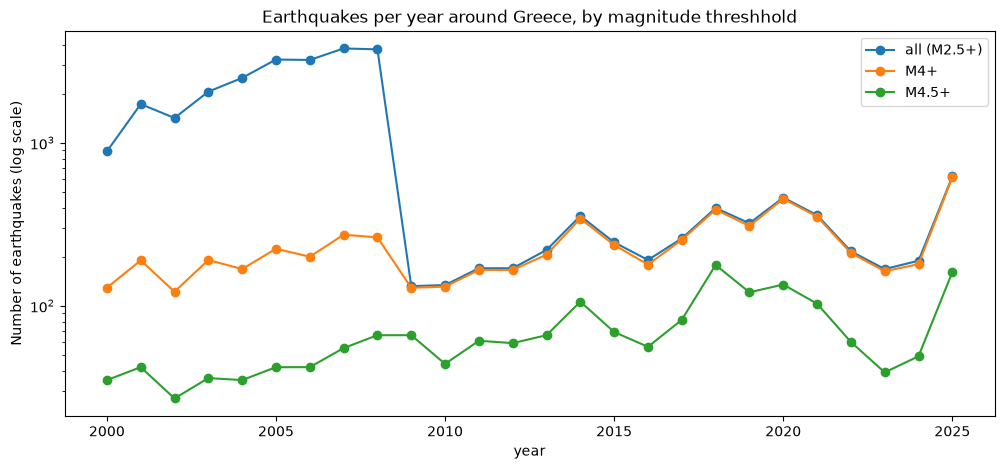

In [5]:
counts.plot(figsize=(12 ,5), marker="o", logy=True)
plt.title("Earthquakes per year around Greece, by magnitude threshhold")
plt.ylabel("Number of earthquakes (log scale)")
plt.show()

Choosing the period and counting earthquakes at each magnitude

We'll use the period from 2009 to 2025 which has more consistent catalog.

In [8]:
recent = eq[eq["year"] >= 2009 ]
mags = recent["mag"].round(1)
freq = mags.value_counts().sort_index()

In [9]:
cumulative = freq[::-1].cumsum()[::-1]

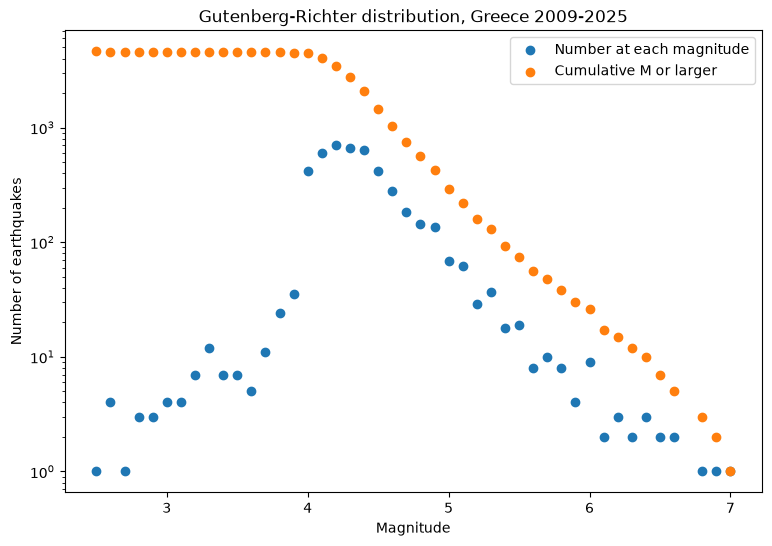

Magnitude of completeness (maximum curvature): 4.2


In [10]:
fig, ax = plt.subplots(figsize=(9,6))
ax.scatter(freq.index, freq.values, label="Number at each magnitude")
ax.scatter(cumulative.index, cumulative.values, label="Cumulative M or larger")
ax.set_yscale("log")
ax.set_xlabel("Magnitude")
ax.set_ylabel("Number of earthquakes")
ax.set_title("Gutenberg-Richter distribution, Greece 2009-2025")
ax.legend()
plt.show()

mc = freq.idxmax()
print("Magnitude of completeness (maximum curvature):", mc)

In [14]:
import numpy as np

def b_value(magnitudes, mc, dm=0.1):
    above = magnitudes[magnitudes >= mc]
    b = np.log10(np.e) / (above.mean() - (mc - dm /2 ))
    error = b/ np.sqrt(len(above))
    return b, error, len(above)
    

In [16]:
for m in [mc,mc +0.2]:
    b, error, n =b_value(mags,m)
    print(f"MC={m:.1f}: b = {b:.2f} +- {error:.2f} (from {n} earthquakes)")

MC=4.2: b = 1.25 +- 0.02 (from 3468 earthquakes)
MC=4.4: b = 1.39 +- 0.03 (from 2096 earthquakes)


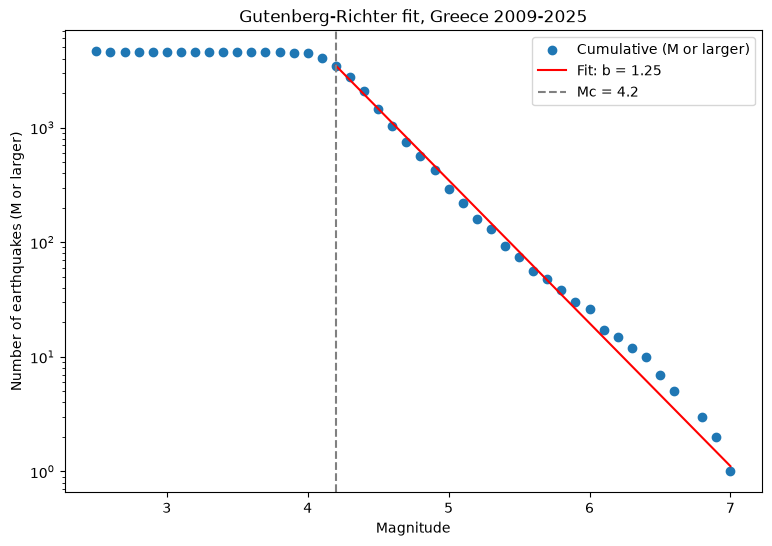

In [17]:
b, err, n = b_value(mags, mc)
a = np.log10(n) + b * mc

m_line = np.linspace(mc, mags.max(), 50)
n_line = 10 ** (a - b * m_line)

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(cumulative.index, cumulative.values, label="Cumulative (M or larger)")
ax.plot(m_line, n_line, color="red", label=f"Fit: b = {b:.2f}")
ax.axvline(mc, color="gray", linestyle="--", label=f"Mc = {mc}")
ax.set_yscale("log")
ax.set_xlabel("Magnitude")
ax.set_ylabel("Number of earthquakes (M or larger)")
ax.set_title("Gutenberg-Richter fit, Greece 2009-2025")
ax.legend()
plt.show()

In [18]:
above_mc=recent[recent["mag"] >= mc]
print(above_mc["magType"].value_counts())
print(above_mc.groupby("magType")["mag"].agg(["count", "mean","max"]).round(2))

magType
mb     2819
mwr     281
mww     281
mwc      42
ml       42
mwb       2
mw        1
Name: count, dtype: int64
         count  mean  max
magType                  
mb        2819  4.42  5.8
ml          42  4.29  4.6
mw           1  5.00  5.0
mwb          2  5.25  5.3
mwc         42  5.21  6.4
mwr        281  4.51  5.4
mww        281  5.21  7.0
